# Three cities, two witnesses — counts from Lamudi, prices from Zameen

**Companion notebook for [_Why invest in Lahore real-estate_](https://ilm.red/blog/why-invest-in-lahore-real-estate) on ilm.red.**

The article argues that Pakistani property data is opaque, so an investor must reason from a
city's *structure* rather than from clean price series. This notebook does that with **two real,
independently checkable datasets** — no invented numbers anywhere:

1. the live listing counts that **Lamudi.pk** — a national property portal headquartered,
   fittingly, in **Gulberg, Lahore** — publishes on its own homepage for Islamabad, Lahore and
   Karachi;
2. the **Zameen.com house-price index**: 187 monthly observations per city (January 2011 to
   July 2026) of the average asking price of houses, read from Zameen's own public index pages
   and shipped beside this notebook as `zameen_house_index.csv`.

Three honesty rules, inherited from the article:

1. **Counts are not prices.** A listing count measures supply and portal adoption, not value.
2. **Asking is not selling.** Nothing on any Pakistani portal is a closed transaction.
3. **One portal is one witness.** Two portals are two witnesses — where they disagree, the
   disagreement is itself the finding. The *shape* is what we trust, not the level.


## 1 · The footprint snapshot (recorded 2026-08-25)

These numbers were read from [lamudi.pk](https://www.lamudi.pk/) on 2026-08-25 — each is the
count the site itself prints next to its category links (e.g. *"Houses for Sale in Lahore
(22291)"*). They are reproducible: open the homepage and count along.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Observed on https://www.lamudi.pk/ — 2026-08-25. Each value appears verbatim on the page.
SNAPSHOT_DATE = "2026-08-25"
SNAPSHOT = {
    "category":  ["houses", "residential_plots", "flats", "commercial_plots", "shops", "offices"],
    "Lahore":    [22291, 30047, 3706, 4110, 597, 219],
    "Karachi":   [11845, 10704, 11946, 918, 1019, 761],
    "Islamabad": [9765, 27748, 4058, 1543, 1754, 436],
}
snap = pd.DataFrame(SNAPSHOT).set_index("category")
snap["source"] = "https://www.lamudi.pk/ (homepage category counts)"
snap[["Lahore", "Karachi", "Islamabad"]]

,Lahore,Karachi,Islamabad
category,,,
houses,22291,11845,9765
residential_plots,30047,10704,27748
flats,3706,11946,4058
commercial_plots,4110,918,1543
shops,597,1019,1754
offices,219,761,436


## 2 · Refresh it live (this is the "run it yourself")

This cell re-reads the homepage and parses today's counts. When it cannot reach the site (no
network, or the page changed shape) it says so and falls back to the recorded snapshot — a
failed fetch must never silently impersonate a measurement.


In [2]:
import re, urllib.request

CITY_RE = re.compile(
    r'(Houses|Residential Plots|Flats|Commercial Plots|Shops|Offices) for Sale in '
    r'(Lahore|Karachi|Islamabad)\s*\((\d+)\)', re.I)
CAT_KEY = {"houses": "houses", "residential plots": "residential_plots", "flats": "flats",
           "commercial plots": "commercial_plots", "shops": "shops", "offices": "offices"}

def fetch_live_counts(timeout=20):
    req = urllib.request.Request("https://www.lamudi.pk/", headers={"User-Agent": "Mozilla/5.0"})
    html = urllib.request.urlopen(req, timeout=timeout).read().decode("utf-8", "replace")
    out = {}
    for cat, city, n in CITY_RE.findall(html):
        out.setdefault(CAT_KEY[cat.lower()], {})[city.title()] = int(n)
    if not out:
        raise ValueError("page fetched but no counts matched — the homepage layout changed")
    return out

try:
    live = fetch_live_counts()
    counts = pd.DataFrame(live).T.reindex(snap.index)[["Lahore", "Karachi", "Islamabad"]]
    counts_date = pd.Timestamp.today().strftime("%Y-%m-%d")
    print(f"live counts fetched {counts_date}")
except Exception as e:
    counts = snap[["Lahore", "Karachi", "Islamabad"]].copy()
    counts_date = SNAPSHOT_DATE
    print(f"live fetch unavailable ({type(e).__name__}) — using the recorded {SNAPSHOT_DATE} snapshot")
counts

live fetch unavailable (URLError) — using the recorded 2026-08-25 snapshot


,Lahore,Karachi,Islamabad
category,,,
houses,22291,11845,9765
residential_plots,30047,10704,27748
flats,3706,11946,4058
commercial_plots,4110,918,1543
shops,597,1019,1754
offices,219,761,436


## 3 · What the composition says (this is the article's argument, in numbers)

Levels depend on portal adoption; *composition* is harder to fake. Three structural readings:

- **Plots-to-houses ratio** — how much of a city's market is bets on land that has no building
  on it yet. The article calls this the speculative frontier.
- **Flats share of homes** — verticality: homes people rent and occupy densely.
- **Commercial per 1,000 homes** — how much shop/office life the portal sees beside the housing.


In [3]:
cities = ["Lahore", "Karachi", "Islamabad"]
homes = counts.loc["houses"] + counts.loc["flats"]
structure = pd.DataFrame({
    "plots_per_house":  (counts.loc["residential_plots"] / counts.loc["houses"]).round(2),
    "flats_share_of_homes": (counts.loc["flats"] / homes).round(2),
    "commercial_per_1k_homes": (1000 * (counts.loc["commercial_plots"] + counts.loc["shops"]
                                        + counts.loc["offices"]) / homes).round(0),
})
structure

,plots_per_house,flats_share_of_homes,commercial_per_1k_homes
Lahore,1.35,0.14,189.0
Karachi,0.90,0.50,113.0
Islamabad,2.84,0.29,270.0


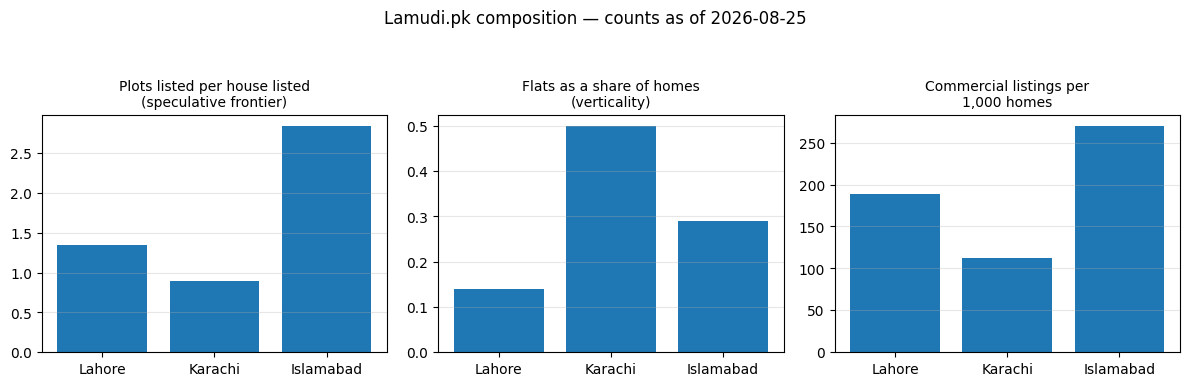

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (col, title) in zip(axes, [
    ("plots_per_house", "Plots listed per house listed\n(speculative frontier)"),
    ("flats_share_of_homes", "Flats as a share of homes\n(verticality)"),
    ("commercial_per_1k_homes", "Commercial listings per\n1,000 homes"),
]):
    ax.bar(cities, structure.loc[cities, col].values)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Lamudi.pk composition — counts as of {counts_date}", y=1.06)
plt.tight_layout(); plt.show()

Read against the article's thesis, from the recorded snapshot:

- **Islamabad lists ~2.8 plots for every house** — by far the highest of the three. The planned
  city's market is dominated by paper: sectors that exist as files (B-17, D-18, the Gulberg of
  Islamabad) before they exist as streets. That is the "creature of the state" pattern.
- **Karachi's flats share (~50%) dwarfs Lahore's (~14%) and Islamabad's (~29%)** — the port
  megacity builds up, and its rental stock looks like it.
- **Lahore leads houses and commercial plots outright** — horizontal, mixed-use, lived-in
  inventory. This is the "grown city" signature the article bets on: things standing on land,
  with commerce beside them, rather than files about land.

None of this prices anything. It is the *shape* of three markets, from one honest witness.


## 4 · Toward a real forecast — collect first, then extrapolate

One snapshot cannot forecast. The honest path: **run this notebook on a schedule** — the cell
below appends today's counts to `lamudi_series.csv`; six weekly rows make a series worth
fitting.


In [5]:
from pathlib import Path
SERIES = Path("lamudi_series.csv")
row = counts[cities].T.assign(date=counts_date).reset_index(names="city")
if SERIES.exists():
    hist = pd.read_csv(SERIES)
    hist = pd.concat([hist[hist["date"] != counts_date], row])
else:
    hist = row
hist.to_csv(SERIES, index=False)
print(f"{SERIES}: {hist['date'].nunique()} dated observation(s) for {hist['city'].nunique()} cities")

lamudi_series.csv: 1 dated observation(s) for 3 cities


## 5 · A real price series — the Zameen house-price index, 2011 to 2026

`zameen_house_index.csv` beside this notebook holds **187 monthly observations per city** of the
average asking price of houses, from Zameen.com's public price index. Provenance, exactly:

- Read on **2026-08-26** from the server-rendered payload (`index_values`) of these three public
  pages — the same numbers the on-page "Price Change Graph" draws:
  [Lahore](https://www.zameen.com/index/buy/houses/lahore-1/) ·
  [Karachi](https://www.zameen.com/index/buy/houses/karachi-2/) ·
  [Islamabad](https://www.zameen.com/index/buy/houses/islamabad-3/)
- Values are **average asking price in nominal PKR** for houses (all sizes), city-wide.
- Spot-check: the Lahore page's headline "PKR 5.09 Crore" is this CSV's 2026-07 row
  (50,866,816 PKR). Open the page and compare — that is the whole verification.

Nominal PKR matters: the rupee lost roughly two-thirds of its dollar value between 2021 and
2024, so a flat nominal line is a steep real-terms decline. The index is also asking prices on
one portal — rule 2 and rule 3 above apply in full.


In [6]:
from pathlib import Path
import numpy as np

ZAMEEN_CSV = Path("zameen_house_index.csv")
zameen = pd.read_csv(ZAMEEN_CSV, parse_dates=["month"]).set_index("month").sort_index()
zameen.columns = ["Lahore", "Karachi", "Islamabad"]
print(f"{len(zameen)} months, {zameen.index[0]:%Y-%m} to {zameen.index[-1]:%Y-%m} — source: zameen.com index pages, read 2026-08-26")
zameen.tail(3).round(0).astype(int)

187 months, 2011-01 to 2026-07 — source: zameen.com index pages, read 2026-08-26


,Lahore,Karachi,Islamabad
month,,,
2026-05-01,49819616,84692718,92012052
2026-06-01,50317344,87406086,92075808
2026-07-01,50866816,89166024,93630240


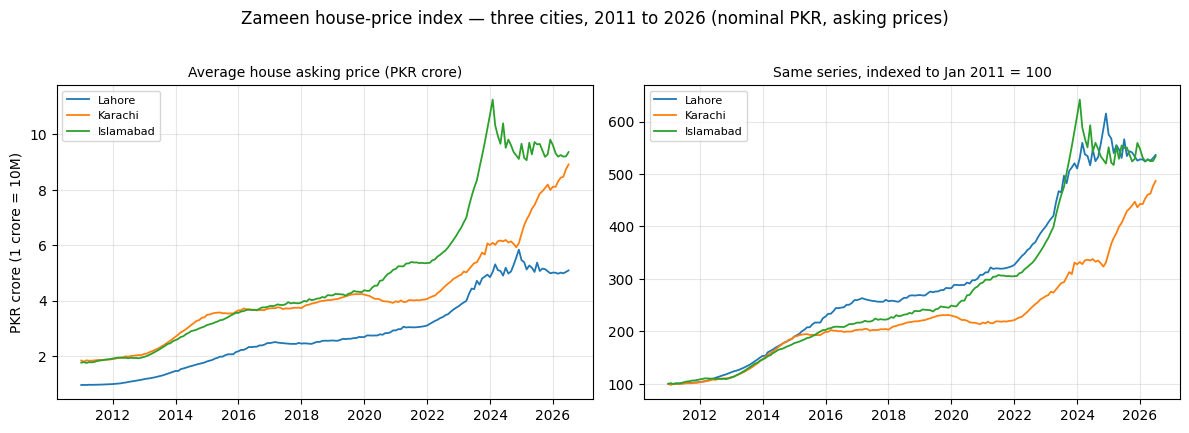

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for city in cities:
    ax1.plot(zameen.index, zameen[city] / 1e7, lw=1.3, label=city)
    ax2.plot(zameen.index, 100 * zameen[city] / zameen[city].iloc[0], lw=1.3, label=city)
ax1.set_title("Average house asking price (PKR crore)", fontsize=10)
ax1.set_ylabel("PKR crore (1 crore = 10M)")
ax2.set_title("Same series, indexed to Jan 2011 = 100", fontsize=10)
for ax in (ax1, ax2):
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle("Zameen house-price index — three cities, 2011 to 2026 (nominal PKR, asking prices)", y=1.02)
plt.tight_layout(); plt.show()

What the real series says — every figure below is computed in the next cell from the CSV,
so a re-run re-derives it rather than trusting this prose:

- **The long march is similar, the recent path is not.** All three cities multiplied roughly
  5x in nominal PKR since 2011 — and then diverged hard after 2024.
- **Karachi houses are the outlier of the last two years**, up over 40% while the other two
  drifted sideways or down in nominal terms.
- **Islamabad is off its early-2024 peak** — the sharp 2023 run-up partially unwound, which is
  what a thin, speculative market looks like on the way down. Read that against its
  plots-per-house ratio in section 3.
- **Lahore is the quiet one**: smallest recent swings in either direction. Flat nominal during
  high inflation is a real-terms decline — the article's case is about the street-level economy,
  and this index neither proves nor breaks it. That honesty survives contact with real data.


In [8]:
def pct(a, b):
    return 100 * (b / a - 1)

last = zameen.index[-1]
rows = []
for city in cities:
    s = zameen[city]
    peak_month = s.idxmax()
    rows.append({
        "city": city,
        "latest (PKR crore)": round(s.iloc[-1] / 1e7, 2),
        "since 2011 (x)": round(s.iloc[-1] / s.iloc[0], 2),
        "12-month %": round(pct(s.loc[last - pd.DateOffset(months=12)], s.iloc[-1]), 1),
        "24-month %": round(pct(s.loc[last - pd.DateOffset(months=24)], s.iloc[-1]), 1),
        "vs own peak %": round(pct(s.max(), s.iloc[-1]), 1),
        "peak month": f"{peak_month:%Y-%m}",
    })
takeaways = pd.DataFrame(rows).set_index("city")
takeaways

,latest (PKR crore),since 2011 (x),12-month %,24-month %,vs own peak %,peak month
city,,,,,,
Lahore,5.09,5.36,-5.3,-1.9,-12.8,2024-12
Karachi,8.92,4.87,16.6,44.1,0.0,2026-07
Islamabad,9.36,5.34,-2.9,-1.6,-16.8,2024-02


### A naive extrapolation on the real series — method, not advice

Least-squares trend on the **last 24 months** (regimes break: fitting one line through 2011-2026
would average a currency crisis into a forecast), extrapolated 12 months with a 95% residual
band. This is the *method* section: the band is honest about noise but silent about policy,
rates and the rupee — which is why the article argues from structure instead.


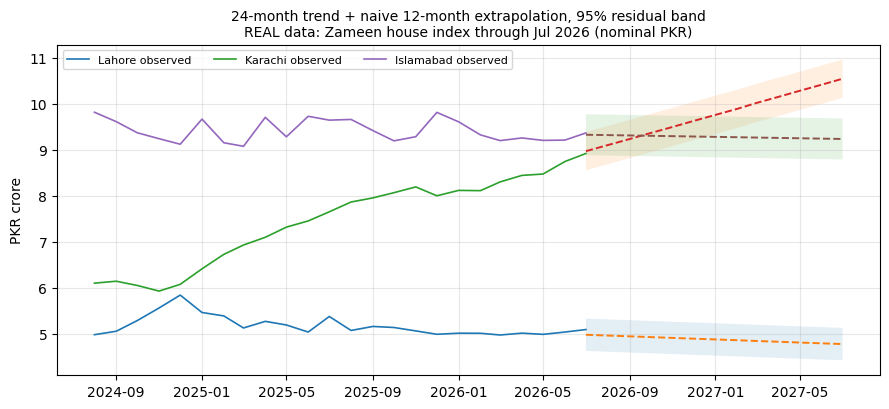

In [9]:
FIT_M = 24  # fit window, months
H = 12      # horizon, months
fig, ax = plt.subplots(figsize=(9, 4.2))
for city in cities:
    y = zameen[city].iloc[-FIT_M:].values / 1e7
    x = np.arange(FIT_M)
    a, b = np.polyfit(x, y, 1)
    resid = y - (a * x + b)
    band = 1.96 * resid.std()
    xf = np.arange(FIT_M + H)
    yf = a * xf + b
    dates = pd.date_range(zameen.index[-FIT_M], periods=FIT_M + H, freq="MS")
    ax.plot(dates[:FIT_M], y, lw=1.2, label=f"{city} observed")
    ax.plot(dates[FIT_M-1:], yf[FIT_M-1:], "--", lw=1.4)
    ax.fill_between(dates[FIT_M-1:], yf[FIT_M-1:] - band, yf[FIT_M-1:] + band, alpha=0.12)
ax.set_title(f"24-month trend + naive 12-month extrapolation, 95% residual band\n"
             f"REAL data: Zameen house index through {zameen.index[-1]:%b %Y} (nominal PKR)", fontsize=10)
ax.set_ylabel("PKR crore"); ax.legend(fontsize=8, ncol=3); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6 · Limitations, stated the article's way

- **Listing counts confound supply with portal adoption.** A city where Lamudi markets harder
  shows more listings without one extra brick existing.
- **The Zameen index is asking prices, nominal PKR, one portal, opaque methodology.** A trend
  in asking prices is not one in sale prices; Pakistan has no functional MLS. Deflate by CPI or
  the PKR/USD rate before believing any "growth" number, and treat every extrapolation here as
  a sketch of *method*, never as advice.
- **Cross-witness before believing a level.** This notebook now carries two witnesses (Lamudi
  counts, Zameen prices); where they disagree — Karachi looks cheap on counts and hot on
  prices — the disagreement is itself the finding.
- The article's conclusion stands apart from any of this arithmetic: judge a street by its mix,
  its ownership, its movement and its small self-funded improvements — then let numbers argue
  with what your feet saw.
